In [1]:
root = "M://Diploma/experiments/vesuvius/fragments"
from utils import estimate_quality, plot_prediction

### Data & Features

The logical next step is to do some feature engineering to account for the neighborhood of each pixel, since it is undoubtedly important to predict, whether the current pixel has ink. For this study, we focus on the features, following the approach in [scikit-image’s trainable segmentation example](https://scikit-image.org/docs/stable/auto_examples/segmentation/plot_trainable_segmentation.html):
- `raw` - the original intensity
- `mean` - [Gaussian-smoothed brightness](https://scikit-image.org/docs/stable/api/skimage.filters.html#skimage.filters.gaussian)
- `edge` measures [Sobel edge strength](https://scikit-image.org/docs/stable/api/skimage.filters.html#skimage.filters.sobel)
- `curvature` uses [two Hessian eigenvalues](https://scikit-image.org/docs/stable/api/skimage.feature.html#skimage.feature.hessian_matrix_eigvals) to describe local intensity curvature
- `contrast` (custom feature) - local standard deviation, computed with [Gaussian-weighted moments](https://docs.scipy.org/doc/scipy/reference/generated/scipy.ndimage.gaussian_filter.html)
- `gabor` - [Gabor filter](https://scikit-image.org/docs/stable/api/skimage.filters.html#skimage.filters.gabor_kernel) magnitudes at 0, 45, 90, and 135 degrees to capture oriented texture
- `differences` (CT-specific) - differences between successive selected layers
- `depth` summaries (CT-specific): mean, standard deviation, range, linear slope, and mean absolute change

These spatial features are computed separately for each CT layer or the IR image, with neighborhood setting the Gaussian sigma in pixels. 

In [ ]:
import tqdm
import numpy
import typing
import warnings
import PIL.Image
import skimage.util
import scipy.ndimage
import scipy.signal
import skimage.feature
import skimage.filters

warnings.filterwarnings("ignore", category=PIL.Image.DecompressionBombWarning)

DEPTHS = [20, 23, 26, 28, 30, 31, 32, 33, 35, 37, 40]

DEFAULT_GROUPS = ("raw", "mean", "edge", "curvature", "depth")
ALL_GROUPS = ("mean", "edge", "curvature", "contrast", "gabor", "differences", "depth")
SPATIAL_GROUPS = {
    "mean": ["mean"],
    "edge": ["edge"],
    "curvature": ["hessian_max", "hessian_min"],
    "contrast": ["local_std", "local_contrast"],
    "gabor": ["gabor_0", "gabor_45", "gabor_90", "gabor_135"],
}

def feature_names(depths, neighborhood, groups=DEFAULT_GROUPS):
    spatial = [name for group, names in SPATIAL_GROUPS.items() if group in groups for name in names]
    layers = ["IR"] if depths is None else [f"CT_{depth}" for depth in depths]
    names = (layers if "raw" in groups else []) + [f"{layer}_{name}_s{neighborhood}" for layer in layers for name in spatial]
    if depths is not None:
        if "differences" in groups:
            names += [f"CT_{right}_minus_{left}" for left, right in zip(depths, depths[1:])]
        if "depth" in groups:
            names += ["depth_mean", "depth_std", "depth_range", "depth_slope", "depth_change"]
    return names

def depth_std(profile):
    mean = numpy.mean(profile, axis=1, dtype=numpy.float64)
    variance = numpy.einsum("ij,ij->i", profile, profile, dtype=numpy.float64) / profile.shape[1] - mean ** 2
    return numpy.sqrt(numpy.maximum(variance, 0))

def depth_slope(profile, depths):
    centered = numpy.array(depths) - numpy.mean(depths)
    return numpy.einsum("ij,j->i", profile, centered / max(numpy.sum(centered ** 2), 1))

def depth_change(profile):
    change = numpy.zeros(len(profile), dtype=numpy.float32)
    for i in range(profile.shape[1] - 1):
        change += numpy.abs(profile[:, i + 1] - profile[:, i])
    return change / max(profile.shape[1] - 1, 1)

def curvature(smoothed):
    hessian = skimage.feature.hessian_matrix(smoothed, sigma=0, use_gaussian_derivatives=False)
    return skimage.feature.hessian_matrix_eigvals(hessian)

def local_std(image, neighborhood):
    mean = scipy.ndimage.gaussian_filter(image, neighborhood, output=numpy.float64, mode="nearest")
    square_mean = scipy.ndimage.gaussian_filter(numpy.square(image, dtype=numpy.float64), neighborhood, mode="nearest")
    return numpy.sqrt(numpy.maximum(square_mean - mean ** 2, 0))

def gabor_strength(image, neighborhood, angle):
    kernel = skimage.filters.gabor_kernel(
        frequency=1 / (2 * neighborhood), theta=numpy.deg2rad(angle),
        sigma_x=neighborhood, sigma_y=neighborhood, dtype=numpy.complex64,
    )
    padding = [(size // 2, size // 2) for size in kernel.shape]
    # Overlap-add convolution keeps large Gabor kernels practical.
    response = scipy.signal.oaconvolve(numpy.pad(image, padding, mode="symmetric"), kernel, mode="valid")
    return numpy.abs(response)

def load_fragment(fragment: int, depths: typing.Optional[typing.List[int]], neighborhood, groups=DEFAULT_GROUPS):
    mask = numpy.array(PIL.Image.open(f"{root}/Frag{fragment}/mask.png")) > 0
    pixels = numpy.flatnonzero(mask)
    ink = numpy.array(PIL.Image.open(f"{root}/Frag{fragment}/inklabels.png")).ravel()[pixels] > 0

    filenames = ["ir.png"] if depths is None else [f"surface_volume/{depth:02d}.tif" for depth in depths]
    features = numpy.empty((len(pixels), len(feature_names(depths, neighborhood, groups))), dtype=numpy.float32)
    n_raw = len(filenames) if "raw" in groups else 0
    needs_profile = depths is not None and ("depth" in groups or "differences" in groups)
    if needs_profile:
        profile = features[:, :n_raw] if "raw" in groups else numpy.empty((len(pixels), len(depths)), dtype=numpy.float32)
    n_spatial = sum(len(names) for group, names in SPATIAL_GROUPS.items() if group in groups)
    needs_smoothing = any(group in groups for group in ("mean", "edge", "curvature", "contrast"))
    if n_spatial:
        nearest = scipy.ndimage.distance_transform_edt(~mask, return_distances=False, return_indices=True)

    for i, filename in enumerate(tqdm.tqdm(filenames)):
        image = numpy.array(PIL.Image.open(f"{root}/Frag{fragment}/{filename}"))
        if "raw" in groups:
            features[:, i] = image.ravel()[pixels]
        elif needs_profile:
            profile[:, i] = image.ravel()[pixels]
        offset = n_raw + n_spatial * i
        if n_spatial:
            image = skimage.util.img_as_float32(image[tuple(nearest)])
        if needs_smoothing:
            smoothed = skimage.filters.gaussian(image, sigma=neighborhood)
        if "mean" in groups:
            features[:, offset] = smoothed.ravel()[pixels]
            offset += 1
        if "edge" in groups:
            features[:, offset] = skimage.filters.sobel(smoothed).ravel()[pixels]
            offset += 1
        if "curvature" in groups:
            largest, smallest = curvature(smoothed)
            features[:, offset] = largest.ravel()[pixels]
            features[:, offset + 1] = smallest.ravel()[pixels]
            offset += 2
        if "contrast" in groups:
            std = local_std(image, neighborhood)
            features[:, offset] = std.ravel()[pixels]
            features[:, offset + 1] = ((image - smoothed) / (std + 1e-6)).ravel()[pixels]
            offset += 2
        if "gabor" in groups:
            features[:, offset] = gabor_strength(image, neighborhood, 0).ravel()[pixels]
            features[:, offset + 1] = gabor_strength(image, neighborhood, 45).ravel()[pixels]
            features[:, offset + 2] = gabor_strength(image, neighborhood, 90).ravel()[pixels]
            features[:, offset + 3] = gabor_strength(image, neighborhood, 135).ravel()[pixels]

    if needs_profile:
        offset = n_raw + len(depths) * n_spatial
        if "differences" in groups:
            for i in range(1, len(depths)):
                features[:, offset + i - 1] = profile[:, i] - profile[:, i - 1]
            offset += len(depths) - 1
        if "depth" in groups:
            features[:, offset] = numpy.mean(profile, axis=1, dtype=numpy.float64)
            features[:, offset + 1] = depth_std(profile)
            features[:, offset + 2] = numpy.ptp(profile, axis=1)
            features[:, offset + 3] = depth_slope(profile, depths)
            features[:, offset + 4] = depth_change(profile)
    return features, ink

def load_fragments(fragments, depths: typing.Optional[typing.List[int]], neighborhood, groups=DEFAULT_GROUPS):
    values = list(load_fragment(fragments[0], depths, neighborhood, groups))
    for fragment in fragments[1:]:
        fragment_values = load_fragment(fragment, depths, neighborhood, groups)
        for i in range(len(values)):
            values[i] = numpy.concatenate([ values[i], fragment_values[i] ])
    return values

### Model

In [3]:
import matplotlib.pyplot as plt

def draw_feature_importance(importances, feature_names, title):
    print('Most important:', numpy.array(feature_names)[numpy.argsort(numpy.abs(importances))[::-1]])
    plt.figure(figsize=(6, 2))
    plt.plot(feature_names, importances)
    plt.xlabel("Feature index (layer)")
    plt.ylabel("Importance")
    plt.title(title)
    plt.show()

In [4]:
import pandas
import catboost
import sklearn.preprocessing

def run_experiment(depths, neighborhood, groups):
    train_X, train_y = load_fragments([1, 2, 3], depths=depths, neighborhood=neighborhood, groups=groups)
    test_X, test_y = load_fragments([4], depths=depths, neighborhood=neighborhood, groups=groups)

    ss = sklearn.preprocessing.StandardScaler(copy=False)
    train_X = ss.fit_transform(train_X)
    test_X = ss.transform(test_X)

    model = catboost.CatBoostClassifier(
        class_weights=[1, 5], iterations=100, depth=4, random_seed=42
    )
    model = model.fit(train_X, train_y)

    display(estimate_quality(model.predict_proba(train_X)[:, 1], train_y))

    preds = model.predict_proba(test_X)[:, 1]
    display(estimate_quality(preds, test_y))
    plot_prediction(preds, fragment=4, ax=None)

    features = feature_names(depths=depths, neighborhood=neighborhood, groups=groups)
    scores = pandas.DataFrame({"feature name": features, "importance": model.feature_importances_})
    scores = scores.sort_values(by='importance')
    display(scores.head(10))
    display(scores.tail(10))

#### IR

100%|██████████| 1/1 [00:17<00:00, 17.29s/it]


Learning rate set to 0.5
0:	learn: 0.4686930	total: 3.19s	remaining: 5m 16s
1:	learn: 0.3841389	total: 6.02s	remaining: 4m 54s
2:	learn: 0.3468147	total: 8.91s	remaining: 4m 48s
3:	learn: 0.3292328	total: 11.5s	remaining: 4m 35s
4:	learn: 0.3197145	total: 14.1s	remaining: 4m 27s
5:	learn: 0.3130997	total: 16.8s	remaining: 4m 22s
6:	learn: 0.3101701	total: 19.3s	remaining: 4m 16s
7:	learn: 0.3077366	total: 22.1s	remaining: 4m 14s
8:	learn: 0.3057353	total: 24.5s	remaining: 4m 7s
9:	learn: 0.3048334	total: 27.1s	remaining: 4m 3s
10:	learn: 0.3036051	total: 29.8s	remaining: 4m 1s
11:	learn: 0.3031582	total: 32.1s	remaining: 3m 55s
12:	learn: 0.3023069	total: 34.7s	remaining: 3m 52s
13:	learn: 0.3016015	total: 37.6s	remaining: 3m 51s
14:	learn: 0.3012944	total: 39.8s	remaining: 3m 45s
15:	learn: 0.3009585	total: 42.7s	remaining: 3m 43s
16:	learn: 0.3005637	total: 45.3s	remaining: 3m 41s
17:	learn: 0.3003596	total: 48.1s	remaining: 3m 39s
18:	learn: 0.3000840	total: 50.5s	remaining: 3m 35s


{'F0.5': 0.6489395815306982,
 'Accuracy': 0.8855224890754108,
 'AUC-ROC': 0.9460573852018763,
 'Precision': 0.6100178624217426,
 'Recall': 0.8713135325938005,
 'F1-score': 0.717620406129893,
 'Jaccard score': 0.5596006124553018}

{'F0.5': 0.3585597728218518,
 'Accuracy': 0.7980801644581149,
 'AUC-ROC': 0.8844089472953133,
 'Precision': 0.31493980033340363,
 'Recall': 0.8039642269093793,
 'F1-score': 0.4525863290026375,
 'Jaccard score': 0.29247921062435084}

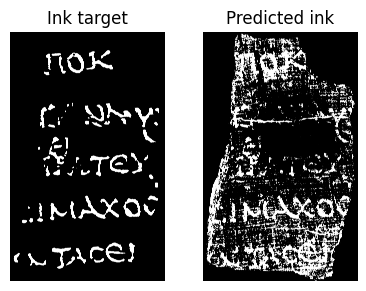

,feature name,importance
9,IR_gabor_90_s3,0.472893
7,IR_gabor_0_s3,0.482499
10,IR_gabor_135_s3,1.589213
8,IR_gabor_45_s3,1.821275
5,IR_local_std_s3,1.891593
3,IR_hessian_max_s3,3.048862
4,IR_hessian_min_s3,4.168195
2,IR_edge_s3,10.019807
6,IR_local_contrast_s3,20.004827
0,IR,22.994431


,feature name,importance
7,IR_gabor_0_s3,0.482499
10,IR_gabor_135_s3,1.589213
8,IR_gabor_45_s3,1.821275
5,IR_local_std_s3,1.891593
3,IR_hessian_max_s3,3.048862
4,IR_hessian_min_s3,4.168195
2,IR_edge_s3,10.019807
6,IR_local_contrast_s3,20.004827
0,IR,22.994431
1,IR_mean_s3,33.506405


In [5]:
run_experiment(None, 3, ALL_GROUPS)

100%|██████████| 1/1 [00:18<00:00, 18.99s/it]


Learning rate set to 0.5
0:	learn: 0.4633904	total: 2.92s	remaining: 4m 48s
1:	learn: 0.3834746	total: 5.7s	remaining: 4m 39s
2:	learn: 0.3384412	total: 8.48s	remaining: 4m 34s
3:	learn: 0.3204678	total: 11.1s	remaining: 4m 25s
4:	learn: 0.3107640	total: 13.7s	remaining: 4m 21s
5:	learn: 0.3049257	total: 16.4s	remaining: 4m 16s
6:	learn: 0.3031793	total: 19.2s	remaining: 4m 14s
7:	learn: 0.3011435	total: 21.5s	remaining: 4m 7s
8:	learn: 0.2997797	total: 23.9s	remaining: 4m 2s
9:	learn: 0.2979802	total: 26.5s	remaining: 3m 58s
10:	learn: 0.2974159	total: 28.6s	remaining: 3m 51s
11:	learn: 0.2961644	total: 31.2s	remaining: 3m 48s
12:	learn: 0.2953236	total: 33.7s	remaining: 3m 45s
13:	learn: 0.2949810	total: 36.2s	remaining: 3m 42s
14:	learn: 0.2946307	total: 38.3s	remaining: 3m 36s
15:	learn: 0.2943373	total: 40.7s	remaining: 3m 33s
16:	learn: 0.2936784	total: 43.4s	remaining: 3m 31s
17:	learn: 0.2934525	total: 45.6s	remaining: 3m 27s
18:	learn: 0.2931431	total: 48.1s	remaining: 3m 24s


{'F0.5': 0.6558953956794554,
 'Accuracy': 0.8885717361892744,
 'AUC-ROC': 0.9490647871608662,
 'Precision': 0.6170980889690326,
 'Recall': 0.8762589948443019,
 'F1-score': 0.7241908275274032,
 'Jaccard score': 0.5676325606939137}

{'F0.5': 0.38467634308724125,
 'Accuracy': 0.8185282287762922,
 'AUC-ROC': 0.8904967419936656,
 'Precision': 0.3405473339478497,
 'Recall': 0.7986311463444419,
 'F1-score': 0.4774874392387256,
 'Jaccard score': 0.31361806236920386}

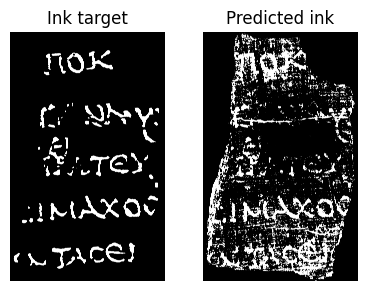

,feature name,importance
10,IR_gabor_135_s5,0.582031
8,IR_gabor_45_s5,0.900679
9,IR_gabor_90_s5,0.932528
7,IR_gabor_0_s5,1.297386
0,IR,2.641414
6,IR_local_contrast_s5,2.683761
3,IR_hessian_max_s5,3.369893
4,IR_hessian_min_s5,6.063511
2,IR_edge_s5,9.956175
5,IR_local_std_s5,17.068207


,feature name,importance
8,IR_gabor_45_s5,0.900679
9,IR_gabor_90_s5,0.932528
7,IR_gabor_0_s5,1.297386
0,IR,2.641414
6,IR_local_contrast_s5,2.683761
3,IR_hessian_max_s5,3.369893
4,IR_hessian_min_s5,6.063511
2,IR_edge_s5,9.956175
5,IR_local_std_s5,17.068207
1,IR_mean_s5,54.504415


In [6]:
run_experiment(None, 5, ALL_GROUPS)

100%|██████████| 1/1 [00:20<00:00, 20.56s/it]


Learning rate set to 0.5
0:	learn: 0.4651126	total: 2.83s	remaining: 4m 40s
1:	learn: 0.3760969	total: 5.6s	remaining: 4m 34s
2:	learn: 0.3348743	total: 8.24s	remaining: 4m 26s
3:	learn: 0.3152805	total: 10.9s	remaining: 4m 20s
4:	learn: 0.3041237	total: 13.6s	remaining: 4m 18s
5:	learn: 0.2991078	total: 16.1s	remaining: 4m 11s
6:	learn: 0.2957050	total: 18.6s	remaining: 4m 6s
7:	learn: 0.2933972	total: 21.3s	remaining: 4m 4s
8:	learn: 0.2918299	total: 23.5s	remaining: 3m 57s
9:	learn: 0.2903292	total: 26.1s	remaining: 3m 54s
10:	learn: 0.2895272	total: 28.7s	remaining: 3m 51s
11:	learn: 0.2891513	total: 30.8s	remaining: 3m 45s
12:	learn: 0.2888786	total: 32.8s	remaining: 3m 39s
13:	learn: 0.2881619	total: 35.3s	remaining: 3m 36s
14:	learn: 0.2877785	total: 37.9s	remaining: 3m 34s
15:	learn: 0.2873887	total: 40.2s	remaining: 3m 31s
16:	learn: 0.2870809	total: 42.6s	remaining: 3m 28s
17:	learn: 0.2869455	total: 44.7s	remaining: 3m 23s
18:	learn: 0.2866423	total: 47.2s	remaining: 3m 21s


{'F0.5': 0.6617955737984302,
 'Accuracy': 0.8911091235018175,
 'AUC-ROC': 0.9514566228830804,
 'Precision': 0.6232848400623936,
 'Recall': 0.8790501101239234,
 'F1-score': 0.7293960740612067,
 'Jaccard score': 0.5740546358868583}

{'F0.5': 0.3896100210700084,
 'Accuracy': 0.8208849591083078,
 'AUC-ROC': 0.8944295315212258,
 'Precision': 0.3449985154837548,
 'Recall': 0.8070421304037649,
 'F1-score': 0.483365474848585,
 'Jaccard score': 0.318709265042168}

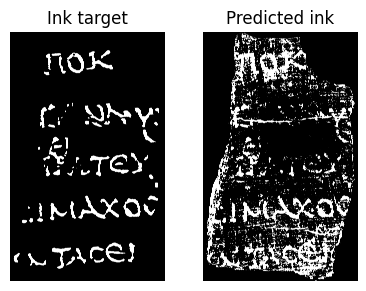

,feature name,importance
8,IR_gabor_45_s7,0.281569
10,IR_gabor_135_s7,0.334906
9,IR_gabor_90_s7,0.336712
7,IR_gabor_0_s7,0.540050
6,IR_local_contrast_s7,3.573885
3,IR_hessian_max_s7,3.637741
4,IR_hessian_min_s7,3.785498
0,IR,5.118363
2,IR_edge_s7,11.552753
5,IR_local_std_s7,18.121536


,feature name,importance
10,IR_gabor_135_s7,0.334906
9,IR_gabor_90_s7,0.336712
7,IR_gabor_0_s7,0.540050
6,IR_local_contrast_s7,3.573885
3,IR_hessian_max_s7,3.637741
4,IR_hessian_min_s7,3.785498
0,IR,5.118363
2,IR_edge_s7,11.552753
5,IR_local_std_s7,18.121536
1,IR_mean_s7,52.716986


In [7]:
run_experiment(None, 7, ALL_GROUPS)

100%|██████████| 1/1 [00:25<00:00, 25.03s/it]


Learning rate set to 0.5
0:	learn: 0.4595489	total: 2.81s	remaining: 4m 38s
1:	learn: 0.3745363	total: 5.41s	remaining: 4m 25s
2:	learn: 0.3282779	total: 7.95s	remaining: 4m 17s
3:	learn: 0.3081286	total: 10.4s	remaining: 4m 10s
4:	learn: 0.2957298	total: 13s	remaining: 4m 7s
5:	learn: 0.2896361	total: 15.6s	remaining: 4m 4s
6:	learn: 0.2863692	total: 18.1s	remaining: 3m 59s
7:	learn: 0.2841252	total: 20.5s	remaining: 3m 56s
8:	learn: 0.2817102	total: 23.1s	remaining: 3m 54s
9:	learn: 0.2802756	total: 25.9s	remaining: 3m 52s
10:	learn: 0.2797217	total: 28s	remaining: 3m 46s
11:	learn: 0.2788103	total: 30.6s	remaining: 3m 44s
12:	learn: 0.2783031	total: 32.8s	remaining: 3m 39s
13:	learn: 0.2777935	total: 35.3s	remaining: 3m 36s
14:	learn: 0.2768389	total: 38s	remaining: 3m 35s
15:	learn: 0.2763012	total: 40.3s	remaining: 3m 31s
16:	learn: 0.2758502	total: 42.8s	remaining: 3m 28s
17:	learn: 0.2755264	total: 45.6s	remaining: 3m 27s
18:	learn: 0.2752820	total: 47.9s	remaining: 3m 24s
19:	l

{'F0.5': 0.6701143740455265,
 'Accuracy': 0.8947637903940355,
 'AUC-ROC': 0.9565993110575971,
 'Precision': 0.6313142509138607,
 'Recall': 0.8885539361648035,
 'F1-score': 0.738165016381663,
 'Jaccard score': 0.5849933041679983}

{'F0.5': 0.40630022416613765,
 'Accuracy': 0.8318708581140019,
 'AUC-ROC': 0.9005760028770077,
 'Precision': 0.36140672477703834,
 'Recall': 0.8075533790673497,
 'F1-score': 0.49934162996928544,
 'Jaccard score': 0.3327483722754735}

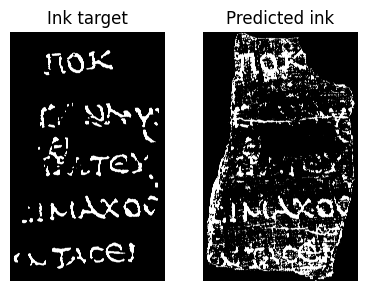

,feature name,importance
7,IR_gabor_0_s13,0.554082
9,IR_gabor_90_s13,0.815173
8,IR_gabor_45_s13,1.388413
10,IR_gabor_135_s13,1.533900
4,IR_hessian_min_s13,2.664934
6,IR_local_contrast_s13,3.396131
3,IR_hessian_max_s13,4.837446
2,IR_edge_s13,7.296893
0,IR,12.840359
5,IR_local_std_s13,22.580539


,feature name,importance
9,IR_gabor_90_s13,0.815173
8,IR_gabor_45_s13,1.388413
10,IR_gabor_135_s13,1.533900
4,IR_hessian_min_s13,2.664934
6,IR_local_contrast_s13,3.396131
3,IR_hessian_max_s13,4.837446
2,IR_edge_s13,7.296893
0,IR,12.840359
5,IR_local_std_s13,22.580539
1,IR_mean_s13,42.092130


In [8]:
run_experiment(None, 13, ALL_GROUPS)

100%|██████████| 1/1 [00:29<00:00, 29.77s/it]


Learning rate set to 0.5
0:	learn: 0.4594964	total: 2.75s	remaining: 4m 32s
1:	learn: 0.3719236	total: 5.34s	remaining: 4m 21s
2:	learn: 0.3272724	total: 7.91s	remaining: 4m 15s
3:	learn: 0.3041714	total: 10.6s	remaining: 4m 13s
4:	learn: 0.2935240	total: 13.1s	remaining: 4m 8s
5:	learn: 0.2859624	total: 15.7s	remaining: 4m 5s
6:	learn: 0.2800155	total: 18.4s	remaining: 4m 3s
7:	learn: 0.2767688	total: 20.9s	remaining: 4m
8:	learn: 0.2744033	total: 23.2s	remaining: 3m 54s
9:	learn: 0.2722915	total: 25.8s	remaining: 3m 51s
10:	learn: 0.2712122	total: 28.2s	remaining: 3m 47s
11:	learn: 0.2697755	total: 30.8s	remaining: 3m 45s
12:	learn: 0.2688091	total: 33.2s	remaining: 3m 41s
13:	learn: 0.2678071	total: 35.4s	remaining: 3m 37s
14:	learn: 0.2665248	total: 38.1s	remaining: 3m 35s
15:	learn: 0.2656326	total: 40.4s	remaining: 3m 32s
16:	learn: 0.2646141	total: 43.2s	remaining: 3m 31s
17:	learn: 0.2639605	total: 45.7s	remaining: 3m 28s
18:	learn: 0.2629103	total: 48.4s	remaining: 3m 26s
19:	

{'F0.5': 0.6809982373769288,
 'Accuracy': 0.8995758415077695,
 'AUC-ROC': 0.9621297930649343,
 'Precision': 0.6415982588899808,
 'Recall': 0.9027454080661622,
 'F1-score': 0.7500919574174332,
 'Jaccard score': 0.6001177141540661}

{'F0.5': 0.4295996518717904,
 'Accuracy': 0.8452830746158388,
 'AUC-ROC': 0.9105250612904573,
 'Precision': 0.3842554075473855,
 'Recall': 0.813669492163276,
 'F1-score': 0.521997501505463,
 'Jaccard score': 0.35317768544854217}

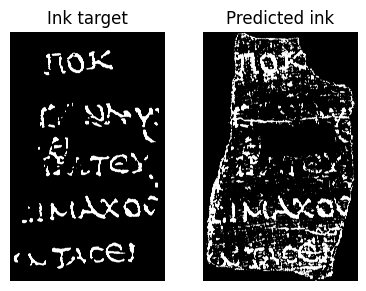

,feature name,importance
7,IR_gabor_0_s21,1.120355
9,IR_gabor_90_s21,1.763318
10,IR_gabor_135_s21,2.315923
8,IR_gabor_45_s21,2.484396
4,IR_hessian_min_s21,4.954122
6,IR_local_contrast_s21,5.297462
3,IR_hessian_max_s21,7.638413
2,IR_edge_s21,11.627137
0,IR,13.669286
5,IR_local_std_s21,15.284666


,feature name,importance
9,IR_gabor_90_s21,1.763318
10,IR_gabor_135_s21,2.315923
8,IR_gabor_45_s21,2.484396
4,IR_hessian_min_s21,4.954122
6,IR_local_contrast_s21,5.297462
3,IR_hessian_max_s21,7.638413
2,IR_edge_s21,11.627137
0,IR,13.669286
5,IR_local_std_s21,15.284666
1,IR_mean_s21,33.844923


In [9]:
run_experiment(None, 21, ALL_GROUPS)

100%|██████████| 1/1 [00:34<00:00, 34.53s/it]


Learning rate set to 0.5
0:	learn: 0.4613999	total: 2.73s	remaining: 4m 30s
1:	learn: 0.3721453	total: 5.43s	remaining: 4m 26s
2:	learn: 0.3227787	total: 8.18s	remaining: 4m 24s
3:	learn: 0.2985346	total: 10.8s	remaining: 4m 18s
4:	learn: 0.2854011	total: 13.3s	remaining: 4m 12s
5:	learn: 0.2768966	total: 15.7s	remaining: 4m 6s
6:	learn: 0.2700998	total: 18.5s	remaining: 4m 5s
7:	learn: 0.2665971	total: 21s	remaining: 4m 1s
8:	learn: 0.2633297	total: 23.7s	remaining: 3m 59s
9:	learn: 0.2606688	total: 26.4s	remaining: 3m 57s
10:	learn: 0.2585417	total: 28.8s	remaining: 3m 52s
11:	learn: 0.2564490	total: 31.3s	remaining: 3m 49s
12:	learn: 0.2550100	total: 33.7s	remaining: 3m 45s
13:	learn: 0.2534388	total: 36.2s	remaining: 3m 42s
14:	learn: 0.2521755	total: 38.9s	remaining: 3m 40s
15:	learn: 0.2511760	total: 41.3s	remaining: 3m 36s
16:	learn: 0.2503521	total: 43.7s	remaining: 3m 33s
17:	learn: 0.2497145	total: 46.2s	remaining: 3m 30s
18:	learn: 0.2484666	total: 48.8s	remaining: 3m 28s
19

{'F0.5': 0.6922504900772262,
 'Accuracy': 0.904519684726793,
 'AUC-ROC': 0.9672102491113932,
 'Precision': 0.6523421024893244,
 'Recall': 0.9165340000431333,
 'F1-score': 0.7621936692463817,
 'Jaccard score': 0.6157616505179225}

{'F0.5': 0.4634087549595178,
 'Accuracy': 0.8630366969148632,
 'AUC-ROC': 0.9231212713385597,
 'Precision': 0.4182198190780242,
 'Recall': 0.8161517703584662,
 'F1-score': 0.5530439110241506,
 'Jaccard score': 0.38221195186067686}

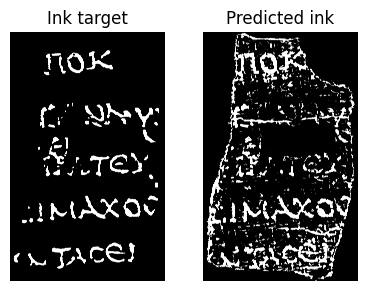

,feature name,importance
7,IR_gabor_0_s30,1.043547
10,IR_gabor_135_s30,1.994201
8,IR_gabor_45_s30,2.030900
9,IR_gabor_90_s30,2.191703
6,IR_local_contrast_s30,4.259843
4,IR_hessian_min_s30,6.847879
2,IR_edge_s30,11.910899
3,IR_hessian_max_s30,11.918552
5,IR_local_std_s30,14.572180
0,IR,15.851385


,feature name,importance
10,IR_gabor_135_s30,1.994201
8,IR_gabor_45_s30,2.030900
9,IR_gabor_90_s30,2.191703
6,IR_local_contrast_s30,4.259843
4,IR_hessian_min_s30,6.847879
2,IR_edge_s30,11.910899
3,IR_hessian_max_s30,11.918552
5,IR_local_std_s30,14.572180
0,IR,15.851385
1,IR_mean_s30,27.378911


In [10]:
run_experiment(None, 30, ALL_GROUPS)

100%|██████████| 1/1 [00:47<00:00, 47.81s/it]


Learning rate set to 0.5
0:	learn: 0.4537927	total: 2.99s	remaining: 4m 56s
1:	learn: 0.3575815	total: 5.54s	remaining: 4m 31s
2:	learn: 0.3076395	total: 8.33s	remaining: 4m 29s
3:	learn: 0.2820292	total: 11.1s	remaining: 4m 26s
4:	learn: 0.2682040	total: 13.6s	remaining: 4m 17s
5:	learn: 0.2576992	total: 16.1s	remaining: 4m 12s
6:	learn: 0.2510906	total: 18.6s	remaining: 4m 7s
7:	learn: 0.2466138	total: 21s	remaining: 4m 1s
8:	learn: 0.2425501	total: 23.7s	remaining: 3m 59s
9:	learn: 0.2394562	total: 26.3s	remaining: 3m 57s
10:	learn: 0.2373072	total: 28.9s	remaining: 3m 53s
11:	learn: 0.2362453	total: 31.3s	remaining: 3m 49s
12:	learn: 0.2338908	total: 33.9s	remaining: 3m 47s
13:	learn: 0.2324017	total: 36.4s	remaining: 3m 43s
14:	learn: 0.2308706	total: 39.1s	remaining: 3m 41s
15:	learn: 0.2296752	total: 41.8s	remaining: 3m 39s
16:	learn: 0.2288461	total: 44.3s	remaining: 3m 36s
17:	learn: 0.2281164	total: 46.7s	remaining: 3m 32s
18:	learn: 0.2271715	total: 49s	remaining: 3m 28s
19:

{'F0.5': 0.7094700063113997,
 'Accuracy': 0.9117984275524461,
 'AUC-ROC': 0.973914791277391,
 'Precision': 0.6696427153455955,
 'Recall': 0.9309429491802218,
 'F1-score': 0.778963823227251,
 'Jaccard score': 0.6379531074059459}

{'F0.5': 0.495958884427339,
 'Accuracy': 0.8779552165387025,
 'AUC-ROC': 0.9341733879842743,
 'Precision': 0.45154332189422114,
 'Recall': 0.8176794429667086,
 'F1-score': 0.5818012442634679,
 'Jaccard score': 0.41023956755716745}

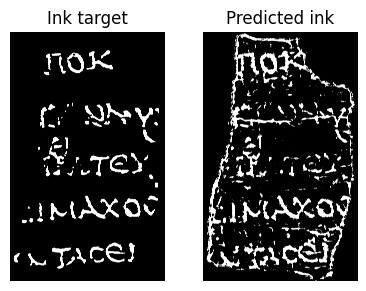

,feature name,importance
9,IR_gabor_90_s50,0.063804
8,IR_gabor_45_s50,0.123262
7,IR_gabor_0_s50,0.131414
6,IR_local_contrast_s50,0.247696
4,IR_hessian_min_s50,0.524682
2,IR_edge_s50,0.890950
1,IR_mean_s50,1.067955
10,IR_gabor_135_s50,1.506958
5,IR_local_std_s50,22.003875
3,IR_hessian_max_s50,35.036031


,feature name,importance
8,IR_gabor_45_s50,0.123262
7,IR_gabor_0_s50,0.131414
6,IR_local_contrast_s50,0.247696
4,IR_hessian_min_s50,0.524682
2,IR_edge_s50,0.890950
1,IR_mean_s50,1.067955
10,IR_gabor_135_s50,1.506958
5,IR_local_std_s50,22.003875
3,IR_hessian_max_s50,35.036031
0,IR,38.403373


In [11]:
run_experiment(None, 50, ALL_GROUPS)

100%|██████████| 1/1 [01:07<00:00, 67.35s/it]


Learning rate set to 0.5
0:	learn: 0.4495155	total: 3.19s	remaining: 5m 15s
1:	learn: 0.3514154	total: 6.09s	remaining: 4m 58s
2:	learn: 0.3054575	total: 8.77s	remaining: 4m 43s
3:	learn: 0.2792650	total: 11.6s	remaining: 4m 38s
4:	learn: 0.2642058	total: 14.1s	remaining: 4m 28s
5:	learn: 0.2551148	total: 17.1s	remaining: 4m 27s
6:	learn: 0.2452515	total: 19.7s	remaining: 4m 22s
7:	learn: 0.2406340	total: 22.4s	remaining: 4m 17s
8:	learn: 0.2359244	total: 25.2s	remaining: 4m 14s
9:	learn: 0.2330716	total: 27.6s	remaining: 4m 8s
10:	learn: 0.2308061	total: 30.4s	remaining: 4m 5s
11:	learn: 0.2290169	total: 33s	remaining: 4m 1s
12:	learn: 0.2278856	total: 35.3s	remaining: 3m 56s
13:	learn: 0.2251664	total: 38.2s	remaining: 3m 54s
14:	learn: 0.2238986	total: 40.7s	remaining: 3m 50s
15:	learn: 0.2224052	total: 43.2s	remaining: 3m 46s
16:	learn: 0.2211564	total: 45.9s	remaining: 3m 43s
17:	learn: 0.2202409	total: 48.5s	remaining: 3m 41s
18:	learn: 0.2190084	total: 51s	remaining: 3m 37s
19:	

{'F0.5': 0.7223860359050196,
 'Accuracy': 0.9168588002484832,
 'AUC-ROC': 0.9771011608848051,
 'Precision': 0.6835823702727692,
 'Recall': 0.9345960236377212,
 'F1-score': 0.7896204367701103,
 'Jaccard score': 0.6523742309916515}

{'F0.5': 0.5063936474279545,
 'Accuracy': 0.8821504442509867,
 'AUC-ROC': 0.9365947750654436,
 'Precision': 0.462037428728518,
 'Recall': 0.8220748366531238,
 'F1-score': 0.5915827673162819,
 'Jaccard score': 0.42003374681026145}

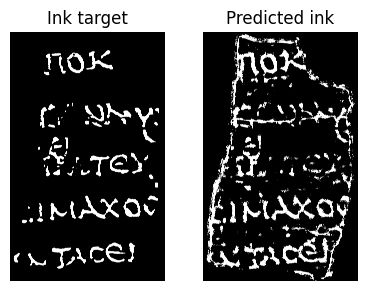

,feature name,importance
9,IR_gabor_90_s75,2.247326
7,IR_gabor_0_s75,2.883952
10,IR_gabor_135_s75,3.214753
6,IR_local_contrast_s75,3.421379
8,IR_gabor_45_s75,3.650697
4,IR_hessian_min_s75,8.737016
1,IR_mean_s75,9.868971
2,IR_edge_s75,10.663804
0,IR,16.755421
5,IR_local_std_s75,18.960178


,feature name,importance
7,IR_gabor_0_s75,2.883952
10,IR_gabor_135_s75,3.214753
6,IR_local_contrast_s75,3.421379
8,IR_gabor_45_s75,3.650697
4,IR_hessian_min_s75,8.737016
1,IR_mean_s75,9.868971
2,IR_edge_s75,10.663804
0,IR,16.755421
5,IR_local_std_s75,18.960178
3,IR_hessian_max_s75,19.596504


In [13]:
run_experiment(None, 75, ALL_GROUPS)

100%|██████████| 1/1 [01:24<00:00, 84.91s/it]


Learning rate set to 0.5
0:	learn: 0.4544590	total: 2.95s	remaining: 4m 52s
1:	learn: 0.3508298	total: 5.8s	remaining: 4m 44s
2:	learn: 0.3051780	total: 8.37s	remaining: 4m 30s
3:	learn: 0.2771721	total: 11.4s	remaining: 4m 33s
4:	learn: 0.2597844	total: 14s	remaining: 4m 26s
5:	learn: 0.2483666	total: 16.8s	remaining: 4m 22s
6:	learn: 0.2429401	total: 19.4s	remaining: 4m 18s
7:	learn: 0.2369220	total: 21.9s	remaining: 4m 11s
8:	learn: 0.2335104	total: 24.6s	remaining: 4m 8s
9:	learn: 0.2288667	total: 27.4s	remaining: 4m 7s
10:	learn: 0.2267386	total: 30.1s	remaining: 4m 3s
11:	learn: 0.2244574	total: 32.7s	remaining: 3m 59s
12:	learn: 0.2220232	total: 35.2s	remaining: 3m 55s
13:	learn: 0.2206486	total: 38s	remaining: 3m 53s
14:	learn: 0.2188811	total: 40.7s	remaining: 3m 50s
15:	learn: 0.2171841	total: 43.2s	remaining: 3m 47s
16:	learn: 0.2157743	total: 45.9s	remaining: 3m 44s
17:	learn: 0.2148190	total: 48.4s	remaining: 3m 40s
18:	learn: 0.2133545	total: 51.1s	remaining: 3m 38s
19:	l

{'F0.5': 0.7360739100835848,
 'Accuracy': 0.9218854151382001,
 'AUC-ROC': 0.9792738174427414,
 'Precision': 0.698940040802183,
 'Recall': 0.934715230758066,
 'F1-score': 0.7998136606880475,
 'Jaccard score': 0.6664079022483856}

{'F0.5': 0.5042621272536192,
 'Accuracy': 0.8809711782802652,
 'AUC-ROC': 0.9382683760765571,
 'Precision': 0.45937010339888434,
 'Recall': 0.8278816410539834,
 'F1-score': 0.5908775446478816,
 'Jaccard score': 0.41932306337438235}

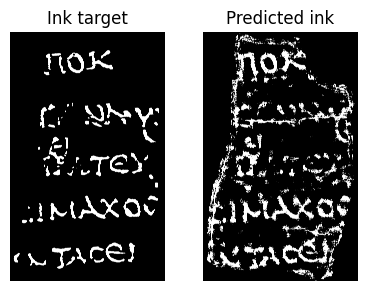

,feature name,importance
9,IR_gabor_90_s100,2.316251
7,IR_gabor_0_s100,2.914899
10,IR_gabor_135_s100,3.327192
8,IR_gabor_45_s100,4.931612
6,IR_local_contrast_s100,6.002548
1,IR_mean_s100,9.297148
4,IR_hessian_min_s100,9.735462
2,IR_edge_s100,10.203406
3,IR_hessian_max_s100,13.162457
5,IR_local_std_s100,18.993266


,feature name,importance
7,IR_gabor_0_s100,2.914899
10,IR_gabor_135_s100,3.327192
8,IR_gabor_45_s100,4.931612
6,IR_local_contrast_s100,6.002548
1,IR_mean_s100,9.297148
4,IR_hessian_min_s100,9.735462
2,IR_edge_s100,10.203406
3,IR_hessian_max_s100,13.162457
5,IR_local_std_s100,18.993266
0,IR,19.115758


In [14]:
run_experiment(None, 100, ALL_GROUPS)

#### CT

Fitting all features into RAM turned out to be impossible: the limit is around 70 features. Thus, we perform several experiments with different groups of features to remove the least effective ones, according to the catboost's feature importance, and get `BEST_GROUPS` - the set of feature we use for the primary experiments.

100%|██████████| 11/11 [01:57<00:00, 10.68s/it]


Learning rate set to 0.5
0:	learn: 0.6793828	total: 12.4s	remaining: 20m 30s
1:	learn: 0.6712663	total: 18.7s	remaining: 15m 18s
2:	learn: 0.6702535	total: 26.6s	remaining: 14m 19s
3:	learn: 0.6656005	total: 32.7s	remaining: 13m 5s
4:	learn: 0.6641673	total: 38.8s	remaining: 12m 17s
5:	learn: 0.6630464	total: 46.2s	remaining: 12m 4s
6:	learn: 0.6618383	total: 51.6s	remaining: 11m 25s
7:	learn: 0.6610553	total: 58s	remaining: 11m 6s
8:	learn: 0.6603377	total: 1m 3s	remaining: 10m 42s
9:	learn: 0.6597390	total: 1m 9s	remaining: 10m 25s
10:	learn: 0.6592237	total: 1m 14s	remaining: 10m 5s
11:	learn: 0.6588236	total: 1m 20s	remaining: 9m 50s
12:	learn: 0.6583029	total: 1m 27s	remaining: 9m 44s
13:	learn: 0.6578614	total: 1m 32s	remaining: 9m 29s
14:	learn: 0.6573886	total: 1m 39s	remaining: 9m 23s
15:	learn: 0.6568015	total: 1m 45s	remaining: 9m 13s
16:	learn: 0.6562973	total: 1m 51s	remaining: 9m 2s
17:	learn: 0.6559834	total: 1m 56s	remaining: 8m 50s
18:	learn: 0.6554048	total: 2m 2s	rem

{'F0.5': 0.27350850005187644,
 'Accuracy': 0.5888138022621581,
 'AUC-ROC': 0.6737762069585032,
 'Precision': 0.23837164807504455,
 'Recall': 0.6664674502773681,
 'F1-score': 0.35114960173640564,
 'Jaccard score': 0.21296632011382086}

{'F0.5': 0.1351020957343793,
 'Accuracy': 0.3905653903037065,
 'AUC-ROC': 0.5493777505560569,
 'Precision': 0.11238304636696395,
 'Recall': 0.7059697662680431,
 'F1-score': 0.19389933473977594,
 'Jaccard score': 0.10735798865997251}

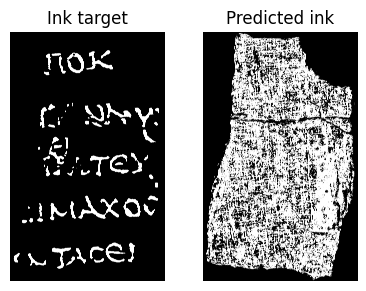

,feature name,importance
58,depth_slope,0.000000
56,depth_std,0.000000
10,CT_40,0.000000
6,CT_32,0.000000
8,CT_35,0.000000
21,CT_26_hessian_max_s25,0.044331
9,CT_37,0.053660
1,CT_23,0.087597
17,CT_23_hessian_max_s25,0.112909
29,CT_30_hessian_max_s25,0.142935


,feature name,importance
39,CT_33_mean_s25,3.734957
11,CT_20_mean_s25,3.746819
43,CT_35_mean_s25,3.854723
47,CT_37_mean_s25,4.254133
52,CT_40_edge_s25,4.390117
27,CT_30_mean_s25,4.886132
15,CT_23_mean_s25,5.123308
23,CT_28_mean_s25,5.396549
51,CT_40_mean_s25,6.701710
57,depth_range,25.348199


In [17]:
run_experiment(DEPTHS, 25, DEFAULT_GROUPS)

100%|██████████| 11/11 [02:51<00:00, 15.62s/it]


Learning rate set to 0.5
0:	learn: 0.6737087	total: 14.7s	remaining: 24m 20s
1:	learn: 0.6681378	total: 21.1s	remaining: 17m 11s
2:	learn: 0.6638887	total: 27.9s	remaining: 15m 2s
3:	learn: 0.6608938	total: 34.7s	remaining: 13m 51s
4:	learn: 0.6598155	total: 40.9s	remaining: 12m 57s
5:	learn: 0.6567015	total: 46.6s	remaining: 12m 10s
6:	learn: 0.6551354	total: 52.7s	remaining: 11m 40s
7:	learn: 0.6539890	total: 59.3s	remaining: 11m 21s
8:	learn: 0.6530222	total: 1m 5s	remaining: 11m 3s
9:	learn: 0.6520299	total: 1m 12s	remaining: 10m 52s
10:	learn: 0.6513740	total: 1m 17s	remaining: 10m 27s
11:	learn: 0.6502631	total: 1m 23s	remaining: 10m 13s
12:	learn: 0.6490590	total: 1m 29s	remaining: 9m 58s
13:	learn: 0.6480097	total: 1m 35s	remaining: 9m 43s
14:	learn: 0.6474215	total: 1m 41s	remaining: 9m 36s
15:	learn: 0.6463922	total: 1m 47s	remaining: 9m 21s
16:	learn: 0.6454902	total: 1m 54s	remaining: 9m 17s
17:	learn: 0.6449924	total: 1m 59s	remaining: 9m 4s
18:	learn: 0.6442619	total: 2m 

{'F0.5': 0.2978239169958235,
 'Accuracy': 0.6147016902220882,
 'AUC-ROC': 0.7172479268875699,
 'Precision': 0.26010923210750925,
 'Recall': 0.7090746095681483,
 'F1-score': 0.3806024084818074,
 'Jaccard score': 0.23502715483539216}

{'F0.5': 0.13428389421011175,
 'Accuracy': 0.37394955191834134,
 'AUC-ROC': 0.5460227693865516,
 'Precision': 0.11157503474234684,
 'Recall': 0.7224214749599862,
 'F1-score': 0.19329625539091733,
 'Jaccard score': 0.10698835155884448}

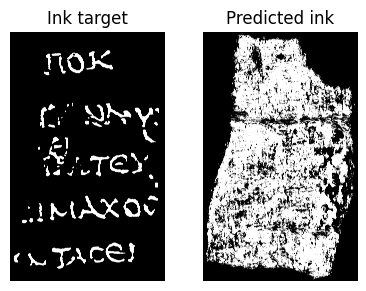

,feature name,importance
6,CT_32,0.000000
8,CT_35,0.000000
10,CT_40,0.000000
56,depth_std,0.000000
58,depth_slope,0.000000
1,CT_23,0.022167
2,CT_26,0.070199
9,CT_37,0.076211
0,CT_20,0.085669
7,CT_33,0.097589


,feature name,importance
23,CT_28_mean_s50,3.857020
19,CT_26_mean_s50,4.385701
31,CT_31_mean_s50,4.709048
43,CT_35_mean_s50,4.712636
27,CT_30_mean_s50,4.974266
15,CT_23_mean_s50,5.502664
47,CT_37_mean_s50,8.379558
51,CT_40_mean_s50,8.637734
11,CT_20_mean_s50,9.208809
57,depth_range,13.810322


In [16]:
run_experiment(DEPTHS, 50, DEFAULT_GROUPS)

100%|██████████| 11/11 [03:47<00:00, 20.67s/it]


Learning rate set to 0.5
0:	learn: 0.6803167	total: 14.4s	remaining: 23m 43s
1:	learn: 0.6675061	total: 20.9s	remaining: 17m 2s
2:	learn: 0.6594183	total: 27.2s	remaining: 14m 38s
3:	learn: 0.6579650	total: 33.3s	remaining: 13m 20s
4:	learn: 0.6540568	total: 38.9s	remaining: 12m 19s
5:	learn: 0.6502050	total: 44.2s	remaining: 11m 33s
6:	learn: 0.6486522	total: 50s	remaining: 11m 4s
7:	learn: 0.6465984	total: 56s	remaining: 10m 44s
8:	learn: 0.6458635	total: 1m 1s	remaining: 10m 24s
9:	learn: 0.6438007	total: 1m 8s	remaining: 10m 13s
10:	learn: 0.6426270	total: 1m 14s	remaining: 10m 3s
11:	learn: 0.6415852	total: 1m 21s	remaining: 9m 55s
12:	learn: 0.6402835	total: 1m 27s	remaining: 9m 44s
13:	learn: 0.6390919	total: 1m 33s	remaining: 9m 35s
14:	learn: 0.6372393	total: 1m 40s	remaining: 9m 30s
15:	learn: 0.6358401	total: 1m 48s	remaining: 9m 29s
16:	learn: 0.6344178	total: 1m 54s	remaining: 9m 17s
17:	learn: 0.6335613	total: 2m	remaining: 9m 8s
18:	learn: 0.6326885	total: 2m 5s	remainin

{'F0.5': 0.32962548087196447,
 'Accuracy': 0.6516659428142366,
 'AUC-ROC': 0.762471736709296,
 'Precision': 0.2892727580932466,
 'Recall': 0.745739713043392,
 'F1-score': 0.41684943829676696,
 'Jaccard score': 0.2633037238405799}

{'F0.5': 0.13303891377871385,
 'Accuracy': 0.40116351540030376,
 'AUC-ROC': 0.53468071623972,
 'Precision': 0.11077544176245013,
 'Recall': 0.6784710086001265,
 'F1-score': 0.19045489698728923,
 'Jaccard score': 0.10525015191398157}

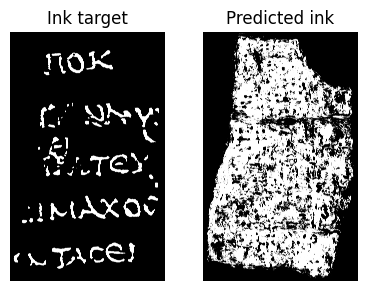

,feature name,importance
1,CT_23,0.000000
5,CT_31,0.000000
6,CT_32,0.000000
8,CT_35,0.000000
10,CT_40,0.000000
56,depth_std,0.000000
58,depth_slope,0.000000
0,CT_20,0.022159
2,CT_26,0.026367
9,CT_37,0.031094


,feature name,importance
20,CT_26_edge_s75,2.841527
19,CT_26_mean_s75,3.445799
23,CT_28_mean_s75,4.135298
15,CT_23_mean_s75,5.673771
27,CT_30_mean_s75,5.769912
57,depth_range,7.400587
43,CT_35_mean_s75,7.697667
47,CT_37_mean_s75,8.066853
11,CT_20_mean_s75,8.643539
51,CT_40_mean_s75,13.238346


In [15]:
run_experiment(DEPTHS, 75, DEFAULT_GROUPS)

Raw features are clearly not useful.

100%|██████████| 11/11 [05:40<00:00, 30.92s/it]


Learning rate set to 0.5
0:	learn: 0.6745883	total: 13s	remaining: 21m 28s
1:	learn: 0.6616289	total: 21.4s	remaining: 17m 28s
2:	learn: 0.6557035	total: 31.1s	remaining: 16m 43s
3:	learn: 0.6558374	total: 40.3s	remaining: 16m 7s
4:	learn: 0.6538852	total: 47.7s	remaining: 15m 5s
5:	learn: 0.6531722	total: 56.3s	remaining: 14m 41s
6:	learn: 0.6525416	total: 1m 5s	remaining: 14m 27s
7:	learn: 0.6518344	total: 1m 12s	remaining: 13m 55s
8:	learn: 0.6512462	total: 1m 19s	remaining: 13m 22s
9:	learn: 0.6506521	total: 1m 26s	remaining: 13m
10:	learn: 0.6501227	total: 1m 33s	remaining: 12m 35s
11:	learn: 0.6484500	total: 1m 41s	remaining: 12m 24s
12:	learn: 0.6480254	total: 1m 49s	remaining: 12m 9s
13:	learn: 0.6476499	total: 1m 56s	remaining: 11m 56s
14:	learn: 0.6471601	total: 2m 3s	remaining: 11m 40s
15:	learn: 0.6467466	total: 2m 10s	remaining: 11m 26s
16:	learn: 0.6464052	total: 2m 16s	remaining: 11m 8s
17:	learn: 0.6458774	total: 2m 23s	remaining: 10m 54s
18:	learn: 0.6454976	total: 2m 

{'F0.5': 0.29138402252903733,
 'Accuracy': 0.6303661927645773,
 'AUC-ROC': 0.6909985529608342,
 'Precision': 0.2564849350378095,
 'Recall': 0.6393747690829387,
 'F1-score': 0.36610642349183875,
 'Jaccard score': 0.22406993255598373}

{'F0.5': 0.13560427754854365,
 'Accuracy': 0.35318830032135534,
 'AUC-ROC': 0.5596393403940717,
 'Precision': 0.11250235323352205,
 'Recall': 0.7591968906016792,
 'F1-score': 0.19596537995026445,
 'Jaccard score': 0.10862617478197945}

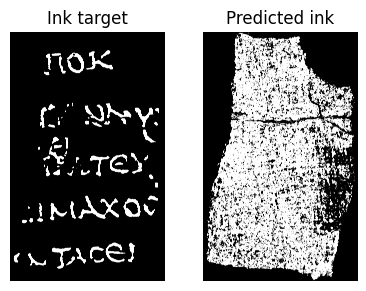

,feature name,importance
43,CT_33_local_contrast_s25,0.000000
33,CT_31_gabor_45_s25,0.000000
29,CT_30_gabor_135_s25,0.000000
1,CT_20_local_contrast_s25,0.039179
61,CT_40_local_contrast_s25,0.039601
7,CT_23_local_contrast_s25,0.042844
13,CT_26_local_contrast_s25,0.048724
45,CT_33_gabor_45_s25,0.050453
65,CT_40_gabor_135_s25,0.056821
31,CT_31_local_contrast_s25,0.069704


,feature name,importance
48,CT_35_local_std_s25,1.260913
18,CT_28_local_std_s25,2.190660
54,CT_37_local_std_s25,2.191890
6,CT_23_local_std_s25,2.432464
36,CT_32_local_std_s25,2.530968
12,CT_26_local_std_s25,3.225118
24,CT_30_local_std_s25,3.549760
60,CT_40_local_std_s25,9.208530
0,CT_20_local_std_s25,16.384200
30,CT_31_local_std_s25,34.273723


In [33]:
run_experiment(DEPTHS, 25, ("contrast", "gabor", "differences"))

Gabor seems unreasonably slow compared to the quality imporvement it gives.

In [35]:
BEST_GROUPS = ("mean", "edge", "contrast", "depth", "curvature")

100%|██████████| 11/11 [01:56<00:00, 10.61s/it]


Learning rate set to 0.5
0:	learn: 0.6724873	total: 17.5s	remaining: 28m 52s
1:	learn: 0.6711494	total: 24.8s	remaining: 20m 16s
2:	learn: 0.6712814	total: 32.5s	remaining: 17m 30s
3:	learn: 0.6696626	total: 40.6s	remaining: 16m 13s
4:	learn: 0.6686776	total: 46.7s	remaining: 14m 47s
5:	learn: 0.6682538	total: 53.2s	remaining: 13m 53s
6:	learn: 0.6677038	total: 60s	remaining: 13m 17s
7:	learn: 0.6665245	total: 1m 8s	remaining: 13m 9s
8:	learn: 0.6660706	total: 1m 14s	remaining: 12m 31s
9:	learn: 0.6652168	total: 1m 21s	remaining: 12m 16s
10:	learn: 0.6651225	total: 1m 29s	remaining: 12m 4s
11:	learn: 0.6647549	total: 1m 35s	remaining: 11m 42s
12:	learn: 0.6641227	total: 1m 43s	remaining: 11m 34s
13:	learn: 0.6638391	total: 1m 51s	remaining: 11m 24s
14:	learn: 0.6634812	total: 1m 59s	remaining: 11m 16s
15:	learn: 0.6630504	total: 2m 6s	remaining: 11m 2s
16:	learn: 0.6628700	total: 2m 13s	remaining: 10m 51s
17:	learn: 0.6624558	total: 2m 20s	remaining: 10m 41s
18:	learn: 0.6621723	total:

{'F0.5': 0.2537599940121113,
 'Accuracy': 0.5689889818869659,
 'AUC-ROC': 0.6364309788697462,
 'Precision': 0.22091747050143098,
 'Recall': 0.6260375033707791,
 'F1-score': 0.3265878965239324,
 'Jaccard score': 0.19516286265979135}

{'F0.5': 0.1372884258382828,
 'Accuracy': 0.3262879294803228,
 'AUC-ROC': 0.56859375254202,
 'Precision': 0.11369558611415395,
 'Recall': 0.8077470765881732,
 'F1-score': 0.1993336775515784,
 'Jaccard score': 0.11069995315986043}

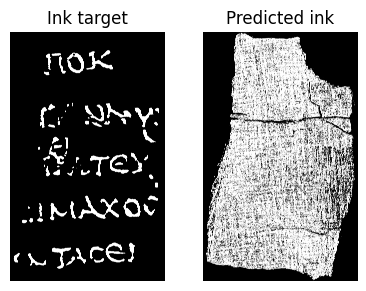

,feature name,importance
17,CT_26_local_contrast_s3,0.000000
62,CT_40_hessian_max_s3,0.000000
41,CT_32_local_contrast_s3,0.000000
23,CT_28_local_contrast_s3,0.000000
5,CT_20_local_contrast_s3,0.000000
29,CT_30_local_contrast_s3,0.000000
65,CT_40_local_contrast_s3,0.000000
11,CT_23_local_contrast_s3,0.000000
3,CT_20_hessian_min_s3,0.021909
8,CT_23_hessian_max_s3,0.023838


,feature name,importance
48,CT_35_mean_s3,2.346555
42,CT_33_mean_s3,2.607095
36,CT_32_mean_s3,3.116886
54,CT_37_mean_s3,3.157102
18,CT_28_mean_s3,3.268522
60,CT_40_mean_s3,3.581119
24,CT_30_mean_s3,5.001972
70,depth_change,6.053640
68,depth_range,14.939397
4,CT_20_local_std_s3,21.044052


In [36]:
run_experiment(DEPTHS, 3, BEST_GROUPS)

100%|██████████| 11/11 [02:19<00:00, 12.68s/it]


Learning rate set to 0.5
0:	learn: 0.6767478	total: 10.2s	remaining: 16m 50s
1:	learn: 0.6712573	total: 18.8s	remaining: 15m 18s
2:	learn: 0.6683306	total: 26.1s	remaining: 14m 2s
3:	learn: 0.6679313	total: 32.9s	remaining: 13m 8s
4:	learn: 0.6669370	total: 39.9s	remaining: 12m 37s
5:	learn: 0.6656908	total: 48.1s	remaining: 12m 33s
6:	learn: 0.6647695	total: 54.8s	remaining: 12m 8s
7:	learn: 0.6645556	total: 1m 1s	remaining: 11m 47s
8:	learn: 0.6628918	total: 1m 10s	remaining: 11m 47s
9:	learn: 0.6626025	total: 1m 16s	remaining: 11m 24s
10:	learn: 0.6623436	total: 1m 23s	remaining: 11m 18s
11:	learn: 0.6615857	total: 1m 30s	remaining: 11m 2s
12:	learn: 0.6606539	total: 1m 38s	remaining: 10m 56s
13:	learn: 0.6601939	total: 1m 45s	remaining: 10m 50s
14:	learn: 0.6600727	total: 1m 51s	remaining: 10m 33s
15:	learn: 0.6596496	total: 1m 58s	remaining: 10m 20s
16:	learn: 0.6593090	total: 2m 6s	remaining: 10m 20s
17:	learn: 0.6589602	total: 2m 13s	remaining: 10m 9s
18:	learn: 0.6587740	total:

{'F0.5': 0.2622120561079548,
 'Accuracy': 0.5843628768912396,
 'AUC-ROC': 0.6500884285056707,
 'Precision': 0.2288604078351449,
 'Recall': 0.6286805641153274,
 'F1-score': 0.3355643520430477,
 'Jaccard score': 0.20160848660922606}

{'F0.5': 0.1387052476376618,
 'Accuracy': 0.34905115199298203,
 'AUC-ROC': 0.572103608260518,
 'Precision': 0.11501746854068548,
 'Recall': 0.7871927980094923,
 'F1-score': 0.20070913896095727,
 'Jaccard score': 0.11154902373319067}

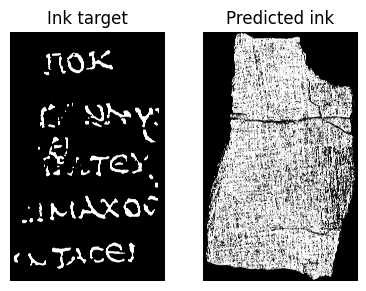

,feature name,importance
35,CT_31_local_contrast_s5,0.000000
17,CT_26_local_contrast_s5,0.000000
69,depth_slope,0.000000
65,CT_40_local_contrast_s5,0.000000
59,CT_37_local_contrast_s5,0.000000
11,CT_23_local_contrast_s5,0.000000
47,CT_33_local_contrast_s5,0.000000
5,CT_20_local_contrast_s5,0.000000
29,CT_30_local_contrast_s5,0.016745
53,CT_35_local_contrast_s5,0.051640


,feature name,importance
16,CT_26_local_std_s5,2.357662
18,CT_28_mean_s5,2.561284
70,depth_change,3.428093
64,CT_40_local_std_s5,4.043938
54,CT_37_mean_s5,4.076747
24,CT_30_mean_s5,4.457598
60,CT_40_mean_s5,4.493537
48,CT_35_mean_s5,5.876552
68,depth_range,6.113069
4,CT_20_local_std_s5,27.289832


In [37]:
run_experiment(DEPTHS, 5, BEST_GROUPS)

100%|██████████| 11/11 [02:34<00:00, 14.04s/it]


Learning rate set to 0.5
0:	learn: 0.6765997	total: 13s	remaining: 21m 25s
1:	learn: 0.6738037	total: 20.5s	remaining: 16m 44s
2:	learn: 0.6682301	total: 28.3s	remaining: 15m 14s
3:	learn: 0.6664339	total: 35.5s	remaining: 14m 11s
4:	learn: 0.6657089	total: 42.6s	remaining: 13m 29s
5:	learn: 0.6623460	total: 49.6s	remaining: 12m 57s
6:	learn: 0.6621071	total: 57.4s	remaining: 12m 42s
7:	learn: 0.6615400	total: 1m 4s	remaining: 12m 27s
8:	learn: 0.6610090	total: 1m 11s	remaining: 12m 4s
9:	learn: 0.6602380	total: 1m 19s	remaining: 11m 54s
10:	learn: 0.6598715	total: 1m 26s	remaining: 11m 36s
11:	learn: 0.6591596	total: 1m 34s	remaining: 11m 30s
12:	learn: 0.6588436	total: 1m 39s	remaining: 11m 3s
13:	learn: 0.6582980	total: 1m 45s	remaining: 10m 49s
14:	learn: 0.6578288	total: 1m 52s	remaining: 10m 39s
15:	learn: 0.6575824	total: 1m 58s	remaining: 10m 24s
16:	learn: 0.6572261	total: 2m 5s	remaining: 10m 10s
17:	learn: 0.6567089	total: 2m 12s	remaining: 10m 3s
18:	learn: 0.6564101	total:

{'F0.5': 0.2678435924860469,
 'Accuracy': 0.5914744403899524,
 'AUC-ROC': 0.6599557939341941,
 'Precision': 0.2339713057755721,
 'Recall': 0.6363357155866871,
 'F1-score': 0.3421420134113297,
 'Jaccard score': 0.2063759478671307}

{'F0.5': 0.1389499341113552,
 'Accuracy': 0.3666054712491173,
 'AUC-ROC': 0.5682763908074185,
 'Precision': 0.11535132579862387,
 'Recall': 0.7648108651077884,
 'F1-score': 0.20046747789636993,
 'Jaccard score': 0.11139975267689303}

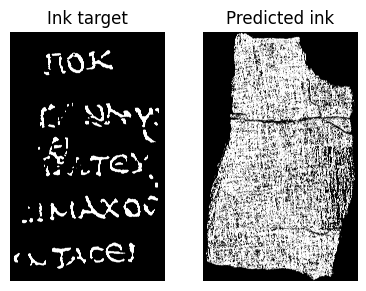

,feature name,importance
35,CT_31_local_contrast_s7,0.000000
33,CT_31_hessian_min_s7,0.000000
69,depth_slope,0.000000
5,CT_20_local_contrast_s7,0.000000
41,CT_32_local_contrast_s7,0.000000
59,CT_37_local_contrast_s7,0.000000
9,CT_23_hessian_min_s7,0.000000
65,CT_40_local_contrast_s7,0.000000
11,CT_23_local_contrast_s7,0.000000
17,CT_26_local_contrast_s7,0.017923


,feature name,importance
22,CT_28_local_std_s7,2.935342
0,CT_20_mean_s7,2.936159
52,CT_35_local_std_s7,3.307873
6,CT_23_mean_s7,3.613669
18,CT_28_mean_s7,4.197062
42,CT_33_mean_s7,4.204934
46,CT_33_local_std_s7,4.840751
68,depth_range,5.655315
54,CT_37_mean_s7,8.049963
4,CT_20_local_std_s7,21.392999


In [38]:
run_experiment(DEPTHS, 7, BEST_GROUPS)

100%|██████████| 11/11 [03:16<00:00, 17.87s/it]


Learning rate set to 0.5
0:	learn: 0.6693297	total: 10.1s	remaining: 16m 40s
1:	learn: 0.6702625	total: 18.8s	remaining: 15m 22s
2:	learn: 0.6681157	total: 25.6s	remaining: 13m 48s
3:	learn: 0.6627743	total: 33.7s	remaining: 13m 27s
4:	learn: 0.6597407	total: 42.3s	remaining: 13m 24s
5:	learn: 0.6578451	total: 50.5s	remaining: 13m 10s
6:	learn: 0.6576071	total: 57.6s	remaining: 12m 44s
7:	learn: 0.6568221	total: 1m 4s	remaining: 12m 23s
8:	learn: 0.6560898	total: 1m 12s	remaining: 12m 12s
9:	learn: 0.6555189	total: 1m 18s	remaining: 11m 46s
10:	learn: 0.6549736	total: 1m 25s	remaining: 11m 28s
11:	learn: 0.6543104	total: 1m 32s	remaining: 11m 14s
12:	learn: 0.6539190	total: 1m 39s	remaining: 11m 6s
13:	learn: 0.6534797	total: 1m 45s	remaining: 10m 47s
14:	learn: 0.6531311	total: 1m 52s	remaining: 10m 39s
15:	learn: 0.6523753	total: 2m	remaining: 10m 30s
16:	learn: 0.6517130	total: 2m 8s	remaining: 10m 28s
17:	learn: 0.6510906	total: 2m 16s	remaining: 10m 20s
18:	learn: 0.6506864	total:

{'F0.5': 0.2795686306050938,
 'Accuracy': 0.6055689946914109,
 'AUC-ROC': 0.6795948258219615,
 'Precision': 0.24461392242733584,
 'Recall': 0.6525723629330634,
 'F1-score': 0.35584200955682027,
 'Jaccard score': 0.21642811191210626}

{'F0.5': 0.1378939218742643,
 'Accuracy': 0.35561614918551154,
 'AUC-ROC': 0.5583700049972595,
 'Precision': 0.1144001770679353,
 'Recall': 0.7723347015073485,
 'F1-score': 0.1992821727055823,
 'Jaccard score': 0.11066818447896647}

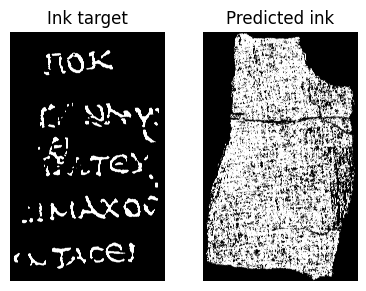

,feature name,importance
35,CT_31_local_contrast_s13,0.000000
41,CT_32_local_contrast_s13,0.000000
69,depth_slope,0.000000
53,CT_35_local_contrast_s13,0.000000
32,CT_31_hessian_max_s13,0.000000
5,CT_20_local_contrast_s13,0.000000
29,CT_30_local_contrast_s13,0.000000
11,CT_23_local_contrast_s13,0.000000
65,CT_40_local_contrast_s13,0.000000
17,CT_26_local_contrast_s13,0.020581


,feature name,importance
34,CT_31_local_std_s13,3.074097
54,CT_37_mean_s13,3.108257
24,CT_30_mean_s13,3.333357
58,CT_37_local_std_s13,3.929514
64,CT_40_local_std_s13,4.732248
6,CT_23_mean_s13,4.745259
60,CT_40_mean_s13,7.284717
68,depth_range,7.610628
4,CT_20_local_std_s13,9.865346
22,CT_28_local_std_s13,12.113200


In [39]:
run_experiment(DEPTHS, 13, BEST_GROUPS)

100%|██████████| 11/11 [03:55<00:00, 21.38s/it]


Learning rate set to 0.5
0:	learn: 0.6690373	total: 11.2s	remaining: 18m 32s
1:	learn: 0.6636434	total: 22.8s	remaining: 18m 34s
2:	learn: 0.6606080	total: 30.9s	remaining: 16m 38s
3:	learn: 0.6592795	total: 37.6s	remaining: 15m 3s
4:	learn: 0.6533606	total: 45.8s	remaining: 14m 30s
5:	learn: 0.6534979	total: 52.4s	remaining: 13m 41s
6:	learn: 0.6519004	total: 59.2s	remaining: 13m 6s
7:	learn: 0.6506763	total: 1m 6s	remaining: 12m 40s
8:	learn: 0.6498190	total: 1m 12s	remaining: 12m 17s
9:	learn: 0.6485685	total: 1m 20s	remaining: 12m 5s
10:	learn: 0.6473253	total: 1m 27s	remaining: 11m 47s
11:	learn: 0.6467843	total: 1m 34s	remaining: 11m 35s
12:	learn: 0.6464008	total: 1m 40s	remaining: 11m 11s
13:	learn: 0.6457680	total: 1m 47s	remaining: 11m 2s
14:	learn: 0.6453476	total: 1m 53s	remaining: 10m 43s
15:	learn: 0.6448079	total: 2m	remaining: 10m 33s
16:	learn: 0.6440493	total: 2m 7s	remaining: 10m 20s
17:	learn: 0.6434119	total: 2m 13s	remaining: 10m 10s
18:	learn: 0.6429839	total: 2m

{'F0.5': 0.2951477422906202,
 'Accuracy': 0.6270447150265267,
 'AUC-ROC': 0.7027759581295183,
 'Precision': 0.2591601408158174,
 'Recall': 0.6639241945038316,
 'F1-score': 0.37279949654666955,
 'Jaccard score': 0.22910483112283636}

{'F0.5': 0.137523443095689,
 'Accuracy': 0.3590928725380923,
 'AUC-ROC': 0.5541398454051841,
 'Precision': 0.11412214815008975,
 'Recall': 0.7649507698120787,
 'F1-score': 0.19861338757287522,
 'Jaccard score': 0.11025583636667008}

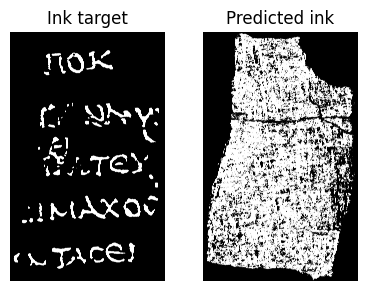

,feature name,importance
37,CT_32_edge_s21,0.0
29,CT_30_local_contrast_s21,0.0
33,CT_31_hessian_min_s21,0.0
26,CT_30_hessian_max_s21,0.0
41,CT_32_local_contrast_s21,0.0
11,CT_23_local_contrast_s21,0.0
63,CT_40_hessian_min_s21,0.0
32,CT_31_hessian_max_s21,0.0
5,CT_20_local_contrast_s21,0.0
2,CT_20_hessian_max_s21,0.0


,feature name,importance
12,CT_26_mean_s21,2.643326
60,CT_40_mean_s21,2.997525
40,CT_32_local_std_s21,3.082366
18,CT_28_mean_s21,3.158174
68,depth_range,3.247252
28,CT_30_local_std_s21,4.403581
42,CT_33_mean_s21,5.149500
64,CT_40_local_std_s21,6.140637
4,CT_20_local_std_s21,6.252927
34,CT_31_local_std_s21,32.323699


In [40]:
run_experiment(DEPTHS, 21, BEST_GROUPS)

100%|██████████| 11/11 [04:40<00:00, 25.47s/it]


Learning rate set to 0.5
0:	learn: 0.6623714	total: 10.5s	remaining: 17m 17s
1:	learn: 0.6578886	total: 17.8s	remaining: 14m 34s
2:	learn: 0.6534245	total: 24.3s	remaining: 13m 4s
3:	learn: 0.6500238	total: 32.6s	remaining: 13m 1s
4:	learn: 0.6495909	total: 40.1s	remaining: 12m 41s
5:	learn: 0.6478166	total: 47s	remaining: 12m 15s
6:	learn: 0.6462073	total: 54s	remaining: 11m 57s
7:	learn: 0.6445960	total: 1m 1s	remaining: 11m 46s
8:	learn: 0.6428883	total: 1m 8s	remaining: 11m 36s
9:	learn: 0.6420297	total: 1m 14s	remaining: 11m 11s
10:	learn: 0.6409190	total: 1m 21s	remaining: 11m 2s
11:	learn: 0.6402503	total: 1m 28s	remaining: 10m 51s
12:	learn: 0.6395966	total: 1m 36s	remaining: 10m 47s
13:	learn: 0.6386096	total: 1m 43s	remaining: 10m 32s
14:	learn: 0.6377476	total: 1m 49s	remaining: 10m 21s
15:	learn: 0.6372791	total: 1m 55s	remaining: 10m 8s
16:	learn: 0.6366763	total: 2m 2s	remaining: 9m 57s
17:	learn: 0.6358545	total: 2m 9s	remaining: 9m 50s
18:	learn: 0.6352954	total: 2m 16s

{'F0.5': 0.3127563464476896,
 'Accuracy': 0.648348604316743,
 'AUC-ROC': 0.7266352006086437,
 'Precision': 0.2755811351247004,
 'Recall': 0.6792997484883246,
 'F1-score': 0.39209538905001584,
 'Jaccard score': 0.24385488192508983}

{'F0.5': 0.13500448873969575,
 'Accuracy': 0.3548845381172249,
 'AUC-ROC': 0.5462346299134013,
 'Precision': 0.11202225731762908,
 'Recall': 0.7526630155515467,
 'F1-score': 0.19501895694789892,
 'Jaccard score': 0.10804487819890621}

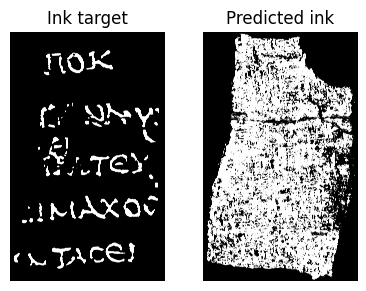

,feature name,importance
41,CT_32_local_contrast_s30,0.0
14,CT_26_hessian_max_s30,0.0
43,CT_33_edge_s30,0.0
32,CT_31_hessian_max_s30,0.0
67,depth_std,0.0
5,CT_20_local_contrast_s30,0.0
23,CT_28_local_contrast_s30,0.0
65,CT_40_local_contrast_s30,0.0
11,CT_23_local_contrast_s30,0.0
31,CT_31_edge_s30,0.0


,feature name,importance
16,CT_26_local_std_s30,2.738716
48,CT_35_mean_s30,2.762645
28,CT_30_local_std_s30,3.416075
64,CT_40_local_std_s30,3.713589
60,CT_40_mean_s30,4.203421
54,CT_37_mean_s30,5.746887
18,CT_28_mean_s30,7.021801
68,depth_range,8.357066
4,CT_20_local_std_s30,9.124410
40,CT_32_local_std_s30,23.085792


In [41]:
run_experiment(DEPTHS, 30, BEST_GROUPS)

100%|██████████| 11/11 [06:47<00:00, 37.07s/it]


Learning rate set to 0.5
0:	learn: 0.6683621	total: 10.7s	remaining: 17m 41s
1:	learn: 0.6551092	total: 18.4s	remaining: 15m 2s
2:	learn: 0.6447613	total: 25.7s	remaining: 13m 49s
3:	learn: 0.6421831	total: 33.3s	remaining: 13m 18s
4:	learn: 0.6410027	total: 39.2s	remaining: 12m 25s
5:	learn: 0.6390192	total: 46.5s	remaining: 12m 8s
6:	learn: 0.6358951	total: 53.7s	remaining: 11m 54s
7:	learn: 0.6329521	total: 1m	remaining: 11m 41s
8:	learn: 0.6317245	total: 1m 8s	remaining: 11m 36s
9:	learn: 0.6308866	total: 1m 15s	remaining: 11m 20s
10:	learn: 0.6294089	total: 1m 23s	remaining: 11m 14s
11:	learn: 0.6277106	total: 1m 30s	remaining: 11m
12:	learn: 0.6266968	total: 1m 37s	remaining: 10m 49s
13:	learn: 0.6257369	total: 1m 43s	remaining: 10m 34s
14:	learn: 0.6246172	total: 1m 49s	remaining: 10m 22s
15:	learn: 0.6238536	total: 1m 55s	remaining: 10m 8s
16:	learn: 0.6225675	total: 2m 2s	remaining: 9m 59s
17:	learn: 0.6216690	total: 2m 8s	remaining: 9m 45s
18:	learn: 0.6208437	total: 2m 13s	r

{'F0.5': 0.344534017844331,
 'Accuracy': 0.6806607775873501,
 'AUC-ROC': 0.7681953936621957,
 'Precision': 0.3050584998670131,
 'Recall': 0.7142265689333572,
 'F1-score': 0.4275170751601509,
 'Jaccard score': 0.2718739061689282}

{'F0.5': 0.1352518536747912,
 'Accuracy': 0.37585524933024606,
 'AUC-ROC': 0.5475069277032983,
 'Precision': 0.11238585032759141,
 'Recall': 0.726532504200937,
 'F1-score': 0.19466011879343142,
 'Jaccard score': 0.10782463779802703}

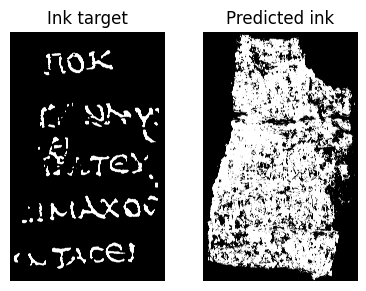

,feature name,importance
29,CT_30_local_contrast_s50,0.0
67,depth_std,0.0
69,depth_slope,0.0
65,CT_40_local_contrast_s50,0.0
5,CT_20_local_contrast_s50,0.0
23,CT_28_local_contrast_s50,0.0
41,CT_32_local_contrast_s50,0.0
11,CT_23_local_contrast_s50,0.0
53,CT_35_local_contrast_s50,0.0
47,CT_33_local_contrast_s50,0.0


In [ ]:
run_experiment(DEPTHS, 50, BEST_GROUPS)

#### Results

Only raw features:
```
IR: 0.316713
CT: 0.134757
```
With feature engineering:
```
IR: 0.506393 (75 neighbors)
CT: 0.138949 (7 neighbors)
```

The improvement is obvious, yet CT scans still produce awful results that are barely better than a constant prediction. Nonetheless, we consider it a successful experiment: getting such a simple model like catboost provide any good predictions (and IR predictions are indeed rather good) on such a complicated problem is not a simple task.
